# Água em Casa: análise descritiva

Global Solution 2026.2 - CitizenTech - Data Science & Statistical Computing
Engenharia de Software, 2º ano - FIAP

Integrante: Bruno Santos Castilho - RM 566799

Projeto: Água em Casa, um sensor na caixa d'água que avisa a família antes de a água acabar durante a redução de pressão da noite.

Para rodar: deixar a pasta `dados/` junto com o notebook e executar todas as células (Run All).

Partes: 1. Contexto e perguntas, 2. Bases e preparação, 3. Análise descritiva, 4. Gráficos, 5. Conclusões

## 1. Contexto e perguntas

Desde agosto de 2025 a Sabesp reduz a pressão da água na Grande São Paulo durante a noite. Desde 2 de agosto de 2026 essa redução vai das 22h às 6h (fonte: Diário do Grande ABC, 31/07/2026, e Correio da Manhã, out/2026). Em casas de bairros altos ou com caixa d'água pequena, a água da caixa pode acabar antes de a pressão voltar, e a família só percebe quando a torneira seca.

O Água em Casa mede o nível da caixa com um sensor ultrassônico (HC-SR04 com ESP32), calcula quantas horas a água ainda dura e manda um aviso quando ela não vai durar até as 6h.

Perguntas da análise:

| | Pergunta | Base |
|---|---|---|
| P1 | Os reservatórios de São Paulo passam por períodos de pouca água? Com que frequência? | Pública (Sabesp) |
| P2 | Em que horário da noite as famílias gastam mais água da caixa? | Simulada |
| P3 | Sem o sistema, em quantas noites a caixa secaria antes das 6h? Quem corre mais risco? | Simulada |
| P4 | Com o aviso, as famílias chegam às 6h com mais água? | Simulada |
| P5 | O número de moradores e o tamanho da caixa mudam o risco? | Simulada |

### Bases usadas

| Arquivo | Conteúdo | Fonte |
|---|---|---|
| `dados/mananciais_sabesp_2000_2024.csv` | Volume diário dos sistemas que abastecem a Grande SP, de 01/01/2000 a 16/10/2024 | Pública: Portal dos Mananciais da Sabesp, organizado por Beatriz Milz no pacote mananciais (CC BY 4.0) - https://github.com/beatrizmilz/mananciais |
| `dados/casas_simuladas.csv` | 20 casas (bairro, altitude, tamanho da caixa, moradores) | Simulada pelo `gerar_dados_simulados.py` |
| `dados/leituras_sensor_simuladas.csv` | Leituras do sensor a cada 15 min, das 22h às 6h, em 30 noites de outubro de 2026 | Simulada pelo mesmo script |

As leituras foram simuladas porque o sensor ainda não está instalado em casas de verdade e o trabalho não pode usar dados pessoais. Cada casa tem só um código e um bairro fictício (A a E).

Valores usados na simulação:
- bairros altos (A e B) não recebem água durante a redução, médios (C e D) recebem 15 L/h e o baixo (E) recebe 40 L/h;
- cada pessoa gasta cerca de 30 L/h às 22h, 18 L/h às 23h e de 2 a 7 L/h de madrugada, com variação entre casas e noites;
- de 1 a 15 de outubro as casas ficam sem o aviso, e de 16 a 30 com o aviso;
- depois de receber o aviso, a família gasta 40% menos naquela noite.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# estilo dos gráficos
AZUL, LARANJA, VERDE_AGUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
VERMELHO, CINZA, TINTA = "#d03b3b", "#898781", "#0b0b0b"
plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7", "axes.grid": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 12, "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.labelsize": 12, "axes.labelcolor": "#52514e", "text.color": TINTA,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 2. Bases e preparação dos dados
### 2.1 Base pública: reservatórios da Sabesp

In [2]:
mananciais = pd.read_csv("dados/mananciais_sabesp_2000_2024.csv", sep=";", decimal=",")
print("Linhas e colunas:", mananciais.shape)
mananciais.head()

Linhas e colunas: (56786, 8)


,data,sistema,volume_porcentagem,volume_variacao,volume_operacional,pluviometria_dia,pluviometria_mensal,pluviometria_hist
0,2024-10-16,Cantareira,47.50,-0.20,466.28,0.00,51.70,130.30
1,2024-10-16,Alto Tietê,43.20,-0.20,241.83,0.00,24.60,109.30
2,2024-10-16,Guarapiranga,36.50,-0.20,62.47,0.00,20.20,114.70
3,2024-10-16,Cotia,34.70,-0.30,5.72,0.00,25.60,120.40
4,2024-10-16,Rio Grande,61.40,-0.30,68.92,0.00,24.40,133.10


In [3]:
# tipos, vazios e duplicadas
print(mananciais.dtypes, "\n")
print("Valores vazios por coluna:\n", mananciais.isna().sum(), "\n")
print("Linhas duplicadas:", mananciais.duplicated().sum())

data                       str
sistema                    str
volume_porcentagem     float64
volume_variacao        float64
volume_operacional     float64
pluviometria_dia       float64
pluviometria_mensal    float64
pluviometria_hist      float64
dtype: object 

Valores vazios por coluna:
 data                     0
sistema                  0
volume_porcentagem       0
volume_variacao          0
volume_operacional       0
pluviometria_dia         0
pluviometria_mensal      0
pluviometria_hist      245
dtype: int64 

Linhas duplicadas: 0


In [4]:
# converte a data e filtra o Sistema Cantareira
mananciais["data"] = pd.to_datetime(mananciais["data"])
cantareira = (mananciais[mananciais["sistema"] == "Cantareira"]
              .sort_values("data").reset_index(drop=True))
cantareira["ano"] = cantareira["data"].dt.year
print("Período:", cantareira["data"].min().date(), "a", cantareira["data"].max().date())
print("Dias com dado:", len(cantareira))
print("Dias com volume negativo:", (cantareira["volume_porcentagem"] < 0).sum())

Período: 2000-01-01 a 2024-10-16
Dias com dado: 9056
Dias com volume negativo: 536


Observações:
- A coluna `pluviometria_hist` tem valores vazios, mas não é usada aqui.
- Os volumes negativos de 2014 e 2015 não são erro. Na crise hídrica a Sabesp usou a reserva técnica (volume morto), e o percentual passou a ficar abaixo de zero. Esses dias foram mantidos.
- 2024 só vai até 16 de outubro.

### 2.2 Base simulada: casas e leituras

| Coluna | Arquivo | Significado |
|---|---|---|
| `casa_id` | os dois | Código da casa (C01 a C20) |
| `bairro`, `altitude` | casas | Bairro e se ele é alto, médio ou baixo |
| `capacidade_litros`, `altura_caixa_cm` | casas | Tamanho da caixa (500 ou 1000 L) e altura da água |
| `moradores` | casas | Número de moradores |
| `data_hora` | leituras | Horário da leitura |
| `distancia_cm` | leituras | Distância medida pelo sensor, da tampa até a água |
| `aviso_ativo` | leituras | 1 se o sistema de aviso estava ligado naquela noite |
| `alerta_enviado` | leituras | 1 se o sistema mandou alerta naquela leitura |

In [5]:
casas = pd.read_csv("dados/casas_simuladas.csv")
leituras_brutas = pd.read_csv("dados/leituras_sensor_simuladas.csv", parse_dates=["data_hora"])
print("Casas:", casas.shape, "| Leituras:", leituras_brutas.shape)
leituras_brutas.head()

Casas: (20, 6) | Leituras: (19859, 6)


,leitura_id,casa_id,data_hora,distancia_cm,aviso_ativo,alerta_enviado
0,1,C01,2026-10-01 22:00:00,16.50,0,0
1,2,C01,2026-10-01 22:15:00,20.30,0,0
2,3,C01,2026-10-01 22:30:00,23.60,0,0
3,4,C01,2026-10-01 22:45:00,27.00,0,0
4,5,C01,2026-10-01 23:00:00,32.40,0,0


In [6]:
# problemas na base do sensor
OFFSET_SENSOR_CM = 3      # sensor fica 3 cm acima da água cheia
bruta = leituras_brutas.merge(casas[["casa_id", "altura_caixa_cm"]], on="casa_id")
vazias = bruta["distancia_cm"].isna()
fora_alcance = (bruta["distancia_cm"] < 0) | (bruta["distancia_cm"] > bruta["altura_caixa_cm"] + OFFSET_SENSOR_CM + 5)
repetidas = bruta.duplicated(subset=["casa_id", "data_hora"])
problemas = pd.Series({
    "Leituras vazias (sensor não respondeu)": vazias.sum(),
    "Fora do alcance (ex.: 400 cm, maior que a caixa)": fora_alcance.sum(),
    "Repetidas (mesma casa e mesmo horário)": repetidas.sum(),
}, name="quantidade")
problemas.to_frame().assign(percentual=lambda d: d["quantidade"] / len(bruta) * 100)

,quantidade,percentual
Leituras vazias (sensor não respondeu),160,0.81
"Fora do alcance (ex.: 400 cm, maior que a caixa)",79,0.40
Repetidas (mesma casa e mesmo horário),59,0.30


In [7]:
# limpeza
leituras = bruta[~(vazias | fora_alcance | repetidas)].copy()
print(f"Antes: {len(bruta):,} | Depois: {len(leituras):,} | Removidas: {len(bruta) - len(leituras):,}")

# distância -> nível (%) e litros
leituras = leituras.drop(columns="altura_caixa_cm").merge(casas, on="casa_id")
altura_agua = leituras["altura_caixa_cm"] - (leituras["distancia_cm"] - OFFSET_SENSOR_CM)
leituras["nivel_pct"] = (altura_agua / leituras["altura_caixa_cm"] * 100).clip(0, 100)
leituras["litros"] = leituras["nivel_pct"] / 100 * leituras["capacidade_litros"]
# noite = data em que a noite começou
leituras["noite"] = (leituras["data_hora"] - pd.Timedelta(hours=12)).dt.normalize()
leituras["hora"] = leituras["data_hora"].dt.hour
leituras["fase"] = np.where(leituras["aviso_ativo"] == 1, "Com aviso", "Sem aviso")
leituras = leituras.sort_values(["casa_id", "data_hora"]).reset_index(drop=True)
leituras[["casa_id", "data_hora", "distancia_cm", "nivel_pct", "litros", "fase"]].head()

Antes: 19,859 | Depois: 19,563 | Removidas: 296


,casa_id,data_hora,distancia_cm,nivel_pct,litros,fase
0,C01,2026-10-01 22:00:00,16.50,76.72,383.62,Sem aviso
1,C01,2026-10-01 22:15:00,20.30,70.17,350.86,Sem aviso
2,C01,2026-10-01 22:30:00,23.60,64.48,322.41,Sem aviso
3,C01,2026-10-01 22:45:00,27.00,58.62,293.10,Sem aviso
4,C01,2026-10-01 23:00:00,32.40,49.31,246.55,Sem aviso


In [8]:
# gasto entre uma leitura e a próxima
leituras["gasto_litros"] = -leituras.groupby(["casa_id", "noite"])["litros"].diff()
minutos = leituras.groupby(["casa_id", "noite"])["data_hora"].diff().dt.total_seconds() / 60
leituras["gasto_litros_hora"] = leituras["gasto_litros"] / minutos * 60

# uma linha por casa e noite
noites = (leituras.groupby(["casa_id", "noite", "fase", "bairro", "altitude",
                            "capacidade_litros", "moradores"])
          .agg(nivel_22h=("nivel_pct", "first"), nivel_6h=("nivel_pct", "last"),
               nivel_minimo=("nivel_pct", "min"), recebeu_alerta=("alerta_enviado", "max"))
          .reset_index())
noites["secou"] = noites["nivel_minimo"] <= 2          # caixa praticamente vazia
noites["gasto_noite_litros"] = (noites["nivel_22h"] - noites["nivel_6h"]) / 100 * noites["capacidade_litros"]
print("Noites analisadas (casa x noite):", len(noites))
noites.head()

Noites analisadas (casa x noite): 600


,casa_id,noite,fase,bairro,altitude,capacidade_litros,moradores,nivel_22h,nivel_6h,nivel_minimo,recebeu_alerta,secou,gasto_noite_litros
0,C01,2026-10-01,Sem aviso,Bairro A,alta,500,4,76.72,12.93,12.93,0,False,318.97
1,C01,2026-10-02,Sem aviso,Bairro A,alta,500,4,86.55,19.14,19.14,0,False,337.07
2,C01,2026-10-03,Sem aviso,Bairro A,alta,500,4,56.55,0.00,0.00,0,True,282.76
3,C01,2026-10-04,Sem aviso,Bairro A,alta,500,4,63.79,0.00,0.00,0,True,318.97
4,C01,2026-10-05,Sem aviso,Bairro A,alta,500,4,72.24,7.07,7.07,0,False,325.86


## 3. Análise descritiva
### P1. Os reservatórios passam por períodos de falta?

In [9]:
v = cantareira["volume_porcentagem"]
resumo = pd.Series({
    "Média (%)": v.mean(), "Mediana (%)": v.median(), "Moda (%)": v.mode().iloc[0],
    "Desvio padrão (p.p.)": v.std(), "Variância": v.var(),
    "Coeficiente de variação (%)": v.std() / v.mean() * 100,
    "Mínimo (%)": v.min(), "1º quartil (%)": v.quantile(.25),
    "3º quartil (%)": v.quantile(.75), "Máximo (%)": v.max(),
    "Assimetria": v.skew(),
})
resumo.to_frame("Volume do Cantareira, 2000-2024")

,"Volume do Cantareira, 2000-2024"
Média (%),47.12
Mediana (%),47.60
Moda (%),47.70
Desvio padrão (p.p.),25.32
Variância,641.03
Coeficiente de variação (%),53.74
Mínimo (%),-24.30
1º quartil (%),34.10
3º quartil (%),63.10
Máximo (%),100.50


In [10]:
por_ano = cantareira.groupby("ano")["volume_porcentagem"].agg(media="mean", minimo="min", maximo="max")
dias_abaixo_30 = cantareira.assign(abaixo=v < 30).groupby("ano")["abaixo"].mean() * 100
por_ano["dias_abaixo_30pct (%)"] = dias_abaixo_30
print("Dias abaixo de 30% em todo o período:", f"{(v < 30).mean() * 100:.1f}%")
print("Anos com algum dia abaixo de 30%:", int((por_ano['minimo'] < 30).sum()), "de", len(por_ano))
por_ano.round(1)

Dias abaixo de 30% em todo o período: 19.2%
Anos com algum dia abaixo de 30%: 12 de 25


,media,minimo,maximo,dias_abaixo_30pct (%)
ano,,,,
2000,48.30,23.50,68.80,17.80
2001,27.80,14.10,41.50,49.90
2002,45.70,24.70,62.90,19.50
2003,28.50,1.60,50.60,49.90
2004,21.70,3.40,37.70,81.40
2005,47.30,30.70,57.70,0.00
2006,52.60,34.50,68.00,0.00
2007,41.70,27.80,51.10,5.80
2008,52.60,32.10,64.30,0.00


### P2. Em que horário as famílias gastam mais água?
Aqui entram só os bairros altos (A e B). Como neles não entra água durante a redução, a queda do nível é o próprio consumo da família.

In [11]:
altos = leituras[leituras["altitude"] == "alta"]
por_hora = (altos.dropna(subset=["gasto_litros_hora"])
            .assign(hora_noite=lambda d: (d["hora"] - 22) % 24)   # 22h vira 0, 6h vira 8
            .groupby(["hora_noite", "hora"])["gasto_litros_hora"]
            .agg(media="mean", mediana="median", desvio="std")
            .reset_index().sort_values("hora_noite"))
por_hora["coef_variacao_%"] = por_hora["desvio"] / por_hora["media"] * 100
por_hora["hora"] = por_hora["hora"].map(lambda h: f"{h:02d}h")
por_hora = por_hora.drop(columns="hora_noite").set_index("hora")
por_hora

,media,mediana,desvio,coef_variacao_%
hora,,,,
22h,118.86,110.00,60.79,51.14
23h,72.32,65.00,52.82,73.04
00h,31.17,30.00,36.58,117.37
01h,12.95,10.34,28.90,223.16
02h,7.56,10.00,26.16,345.83
03h,4.90,5.00,24.97,509.25
04h,8.30,10.00,26.09,314.30
05h,28.72,27.59,34.03,118.46
06h,32.55,30.00,30.46,93.56


In [12]:
gasto_22_24 = altos[altos["hora"].isin([22, 23])]["gasto_litros"].sum()
gasto_total = altos["gasto_litros"].sum()
print(f"Parte do gasto da noite que acontece entre 22h e 0h: {gasto_22_24 / gasto_total * 100:.0f}%")

Parte do gasto da noite que acontece entre 22h e 0h: 61%


### P3. Sem o sistema, em quantas noites a caixa secaria antes das 6h?

In [13]:
sem = noites[noites["fase"] == "Sem aviso"]
print(f"Noites sem aviso: {len(sem)} | Noites em que a caixa secou: {sem['secou'].sum()} "
      f"({sem['secou'].mean() * 100:.1f}%)")
tabela_p3 = (sem.groupby("altitude")
             .agg(noites=("secou", "size"), secou=("secou", "sum"),
                  pct_secou=("secou", "mean"), nivel_6h_medio=("nivel_6h", "mean"),
                  nivel_6h_mediana=("nivel_6h", "median"))
             .reindex(["alta", "média", "baixa"]))
tabela_p3["pct_secou"] *= 100
tabela_p3

Noites sem aviso: 300 | Noites em que a caixa secou: 25 (8.3%)


,noites,secou,pct_secou,nivel_6h_medio,nivel_6h_mediana
altitude,,,,,
alta,120,20,16.67,31.26,32.75
média,120,2,1.67,60.35,62.99
baixa,60,3,5.00,79.32,88.06


In [14]:
# % de noites que secou por caixa e moradores
(pd.crosstab(sem["capacidade_litros"], sem["moradores"], values=sem["secou"],
             aggfunc="mean", margins=True, margins_name="Total")
   .mul(100).round(0).fillna("-"))

moradores,1,2,3,4,5,6,Total
capacidade_litros,,,,,,,
500,-,0.00,0.00,50.00,13.00,20.00,22.00
1000,0.00,0.00,1.00,0.00,13.00,-,2.00
Total,0.00,0.00,1.00,25.00,13.00,20.00,8.00


### P4. Com o aviso, as famílias chegam às 6h com mais água?

In [15]:
comparacao = noites.groupby("fase")["nivel_6h"].describe()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
comparacao["pct_noites_secou"] = noites.groupby("fase")["secou"].mean() * 100
comparacao["pct_noites_com_alerta"] = noites.groupby("fase")["recebeu_alerta"].mean() * 100
comparacao.loc[["Sem aviso", "Com aviso"]]

,count,mean,std,min,25%,50%,75%,max,pct_noites_secou,pct_noites_com_alerta
fase,,,,,,,,,,
Sem aviso,300.00,52.51,29.46,0.00,31.06,54.06,75.34,100.00,8.33,0.00
Com aviso,300.00,59.04,25.12,0.00,42.07,58.06,78.66,100.00,2.33,54.33


In [16]:
por_altitude = (noites.pivot_table(index="altitude", columns="fase", values="secou", aggfunc="mean")
                .mul(100).reindex(["alta", "média", "baixa"])[["Sem aviso", "Com aviso"]])
por_altitude.round(1)

fase,Sem aviso,Com aviso
altitude,,
alta,16.70,5.00
média,1.70,0.80
baixa,5.00,0.00


Indicador de impacto: das noites com aviso em que a caixa ficou abaixo de 20%, em quantas a família recebeu o aviso pelo menos 1 hora antes?

In [17]:
linhas = []
for (casa, noite), g in leituras[leituras["fase"] == "Com aviso"].groupby(["casa_id", "noite"]):
    critico = g[g["nivel_pct"] < 20]
    if critico.empty:
        continue                                   
    hora_critica = critico["data_hora"].iloc[0]
    alertas = g[g["alerta_enviado"] == 1]
    antecedencia = ((hora_critica - alertas["data_hora"].iloc[0]).total_seconds() / 3600
                    if len(alertas) else np.nan)
    linhas.append({"casa_id": casa, "noite": noite, "antecedencia_h": antecedencia})
risco = pd.DataFrame(linhas)
a_tempo = (risco["antecedencia_h"] >= 1)
print(f"Noites de risco com o sistema ligado: {len(risco)}")
print(f"Avisadas pelo menos 1 hora antes: {a_tempo.sum()} ({a_tempo.mean() * 100:.1f}%)")
print(f"Antecedência mediana do aviso: {risco['antecedencia_h'].median():.2f} h")
risco["antecedencia_h"].describe()

Noites de risco com o sistema ligado: 23
Avisadas pelo menos 1 hora antes: 17 (73.9%)
Antecedência mediana do aviso: 1.75 h


count   23.00
mean     2.79
std      2.49
min     -0.25
25%      0.88
50%      1.75
75%      5.25
max      7.00
Name: antecedencia_h, dtype: float64

### P5. Moradores e tamanho da caixa mudam o risco?
Usando só os bairros altos e as noites sem aviso.

In [18]:
print("Moda do número de moradores:", casas["moradores"].mode().iloc[0])
print("Média de moradores:", round(casas["moradores"].mean(), 2))
sem_altos = sem[sem["altitude"] == "alta"]
corr = sem_altos[["moradores", "capacidade_litros", "gasto_noite_litros", "nivel_6h"]].corr()
corr.round(2)

Moda do número de moradores: 3
Média de moradores: 3.35


,moradores,capacidade_litros,gasto_noite_litros,nivel_6h
moradores,1.00,-0.19,0.71,-0.51
capacidade_litros,-0.19,1.00,-0.06,0.59
gasto_noite_litros,0.71,-0.06,1.00,-0.59
nivel_6h,-0.51,0.59,-0.59,1.00


In [19]:
sem_altos.groupby("moradores")["gasto_noite_litros"].describe()[["count", "mean", "50%", "std", "min", "max"]]

,count,mean,50%,std,min,max
moradores,,,,,,
2,30.00,174.50,161.87,59.53,85.00,332.50
3,15.00,250.83,230.00,103.15,151.25,485.00
4,45.00,316.41,318.97,82.63,182.50,570.00
5,30.00,399.42,403.12,87.63,251.25,581.25


## 4. Gráficos

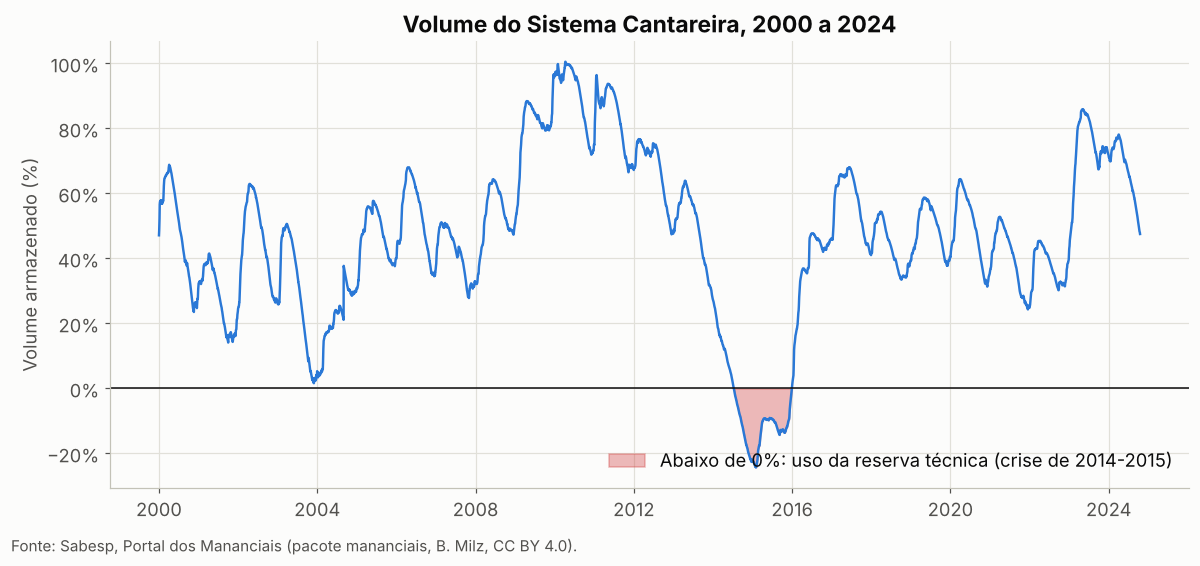

In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(cantareira["data"], cantareira["volume_porcentagem"], color=AZUL, linewidth=1.6)
ax.axhline(0, color=TINTA, linewidth=1)
crise = cantareira[cantareira["volume_porcentagem"] < 0]
ax.fill_between(crise["data"], crise["volume_porcentagem"], 0, color=VERMELHO, alpha=0.35,
                label="Abaixo de 0%: uso da reserva técnica (crise de 2014-2015)")
ax.set_title("Volume do Sistema Cantareira, 2000 a 2024")
ax.set_ylabel("Volume armazenado (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="lower right")
fig.text(0.01, -0.02, "Fonte: Sabesp, Portal dos Mananciais (pacote mananciais, B. Milz, CC BY 4.0).",
         fontsize=10, color="#52514e")
plt.tight_layout(); plt.show()

Gráfico 1: o nível do Cantareira varia muito de um ano para outro. Em 2014 e 2015 ficou abaixo de zero, com uso da reserva técnica. Como os períodos de pouca água se repetem, medidas como a redução de pressão também voltam.

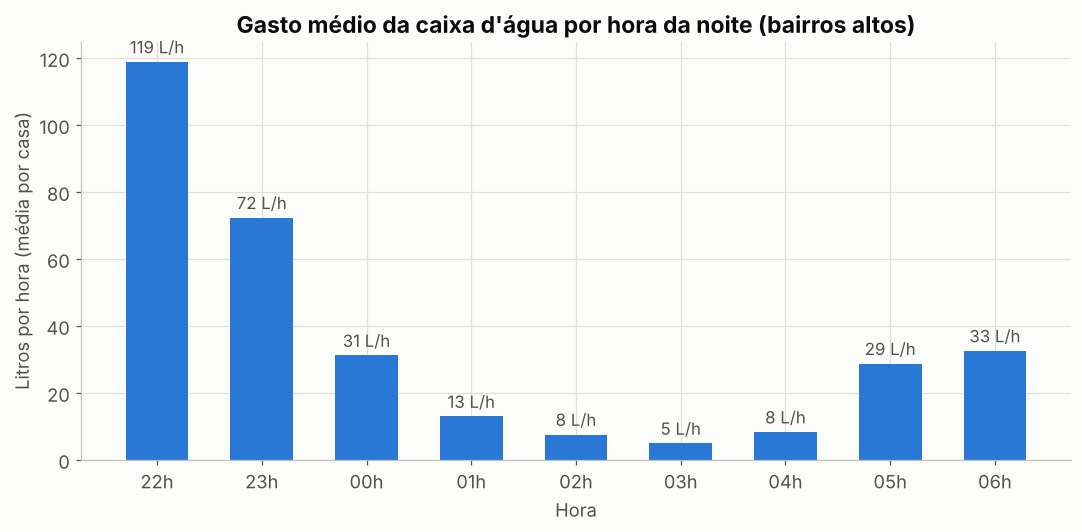

In [21]:
fig, ax = plt.subplots()
barras = ax.bar(por_hora.index, por_hora["media"], color=AZUL, width=0.6)
ax.bar_label(barras, fmt="%.0f L/h", padding=3, fontsize=11, color="#52514e")
ax.set_title("Gasto médio da caixa d'água por hora da noite (bairros altos)")
ax.set_ylabel("Litros por hora (média por casa)")
ax.set_xlabel("Hora")
plt.tight_layout(); plt.show()

Gráfico 2: o gasto fica concentrado às 22h e 23h (banho e louça) e cai bastante de madrugada. Por isso o aviso precisa chegar cedo.

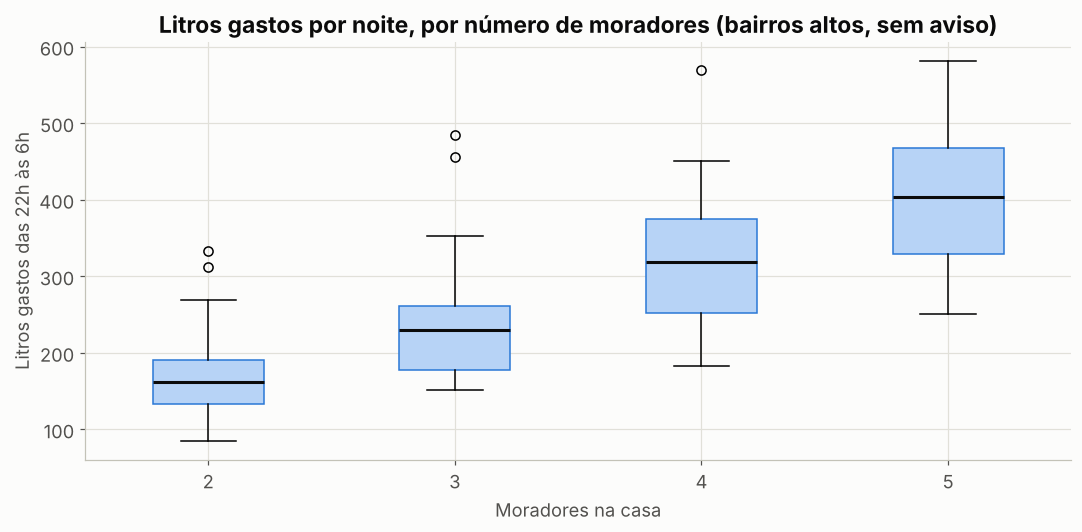

In [22]:
fig, ax = plt.subplots()
grupos = sorted(sem_altos["moradores"].unique())
dados_box = [sem_altos.loc[sem_altos["moradores"] == m, "gasto_noite_litros"] for m in grupos]
caixa = ax.boxplot(dados_box, tick_labels=[str(m) for m in grupos], patch_artist=True,
                   medianprops=dict(color=TINTA, linewidth=2))
for b in caixa["boxes"]:
    b.set(facecolor="#b7d3f6", edgecolor=AZUL)
ax.set_title("Litros gastos por noite, por número de moradores (bairros altos, sem aviso)")
ax.set_xlabel("Moradores na casa")
ax.set_ylabel("Litros gastos das 22h às 6h")
plt.tight_layout(); plt.show()

Gráfico 3: quanto mais moradores, mais água sai da caixa durante a noite, e maior a diferença entre uma noite e outra.

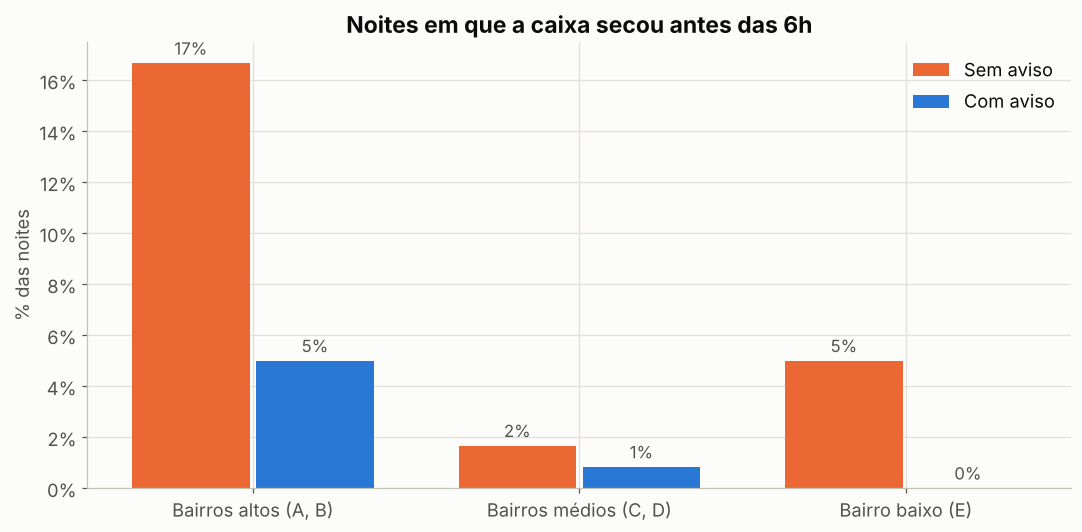

In [23]:
fig, ax = plt.subplots()
x = np.arange(len(por_altitude.index))
largura = 0.36
b1 = ax.bar(x - largura / 2 - 0.01, por_altitude["Sem aviso"], largura, color=LARANJA, label="Sem aviso")
b2 = ax.bar(x + largura / 2 + 0.01, por_altitude["Com aviso"], largura, color=AZUL, label="Com aviso")
ax.bar_label(b1, fmt="%.0f%%", padding=3, fontsize=11, color="#52514e")
ax.bar_label(b2, fmt="%.0f%%", padding=3, fontsize=11, color="#52514e")
ax.set_xticks(x, ["Bairros altos (A, B)", "Bairros médios (C, D)", "Bairro baixo (E)"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Noites em que a caixa secou antes das 6h")
ax.set_ylabel("% das noites")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Gráfico 4: os bairros altos são os que mais secam. Com o aviso, o número de noites sem água cai nos três tipos de bairro.

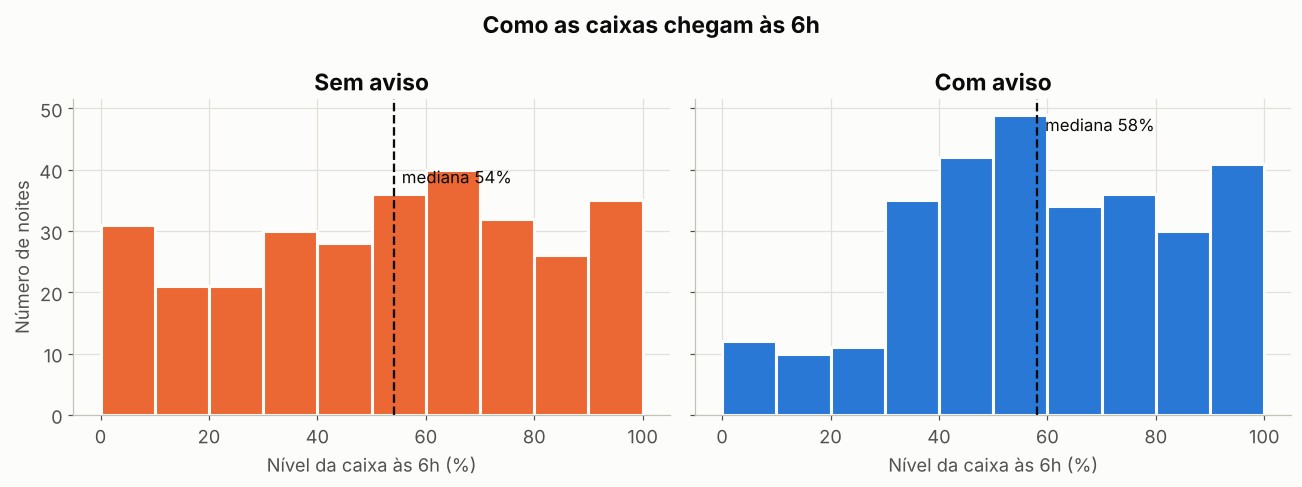

In [24]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
faixas = np.arange(0, 105, 10)
for ax, fase, cor in zip(eixos, ["Sem aviso", "Com aviso"], [LARANJA, AZUL]):
    valores = noites.loc[noites["fase"] == fase, "nivel_6h"]
    ax.hist(valores, bins=faixas, color=cor, edgecolor="#fcfcfb", linewidth=2)
    ax.axvline(valores.median(), color=TINTA, linestyle="--", linewidth=1.5)
    ax.text(valores.median() + 1.5, ax.get_ylim()[1] * 0.9, f"mediana {valores.median():.0f}%",
            fontsize=11, color=TINTA)
    ax.set_title(fase)
    ax.set_xlabel("Nível da caixa às 6h (%)")
eixos[0].set_ylabel("Número de noites")
fig.suptitle("Como as caixas chegam às 6h", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

Gráfico 5: com o aviso, menos noites terminam perto de 0% e a mediana do nível às 6h sobe.

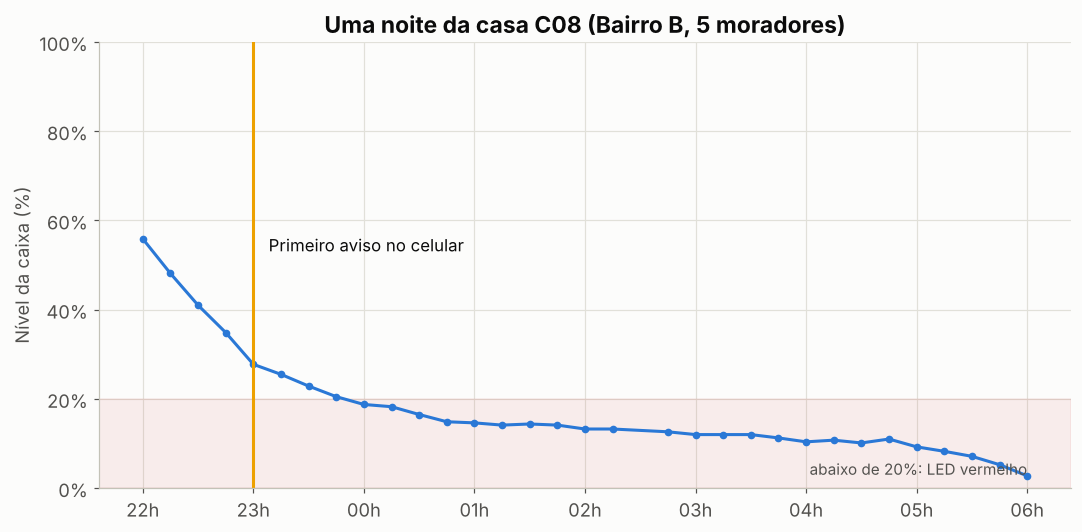

In [25]:
# exemplo: casa de bairro alto que recebeu aviso e não secou
candidatas = noites[(noites["fase"] == "Com aviso") & (noites["recebeu_alerta"] == 1)
                    & (~noites["secou"]) & (noites["altitude"] == "alta")]
exemplo = candidatas.nsmallest(1, "nivel_6h").iloc[0]
serie = leituras[(leituras["casa_id"] == exemplo["casa_id"]) & (leituras["noite"] == exemplo["noite"])]
primeiro_alerta = serie.loc[serie["alerta_enviado"] == 1, "data_hora"].min()
fig, ax = plt.subplots()
ax.plot(serie["data_hora"], serie["nivel_pct"], color=AZUL, linewidth=2, marker="o", markersize=4)
ax.axvline(primeiro_alerta, color=AMARELO, linewidth=2)
ax.annotate("Primeiro aviso no celular", xy=(primeiro_alerta, serie["nivel_pct"].max() * 0.95),
            xytext=(10, 0), textcoords="offset points", fontsize=11, color=TINTA)
ax.axhspan(0, 20, color=VERMELHO, alpha=0.08)
ax.text(serie["data_hora"].iloc[-1], 3, "abaixo de 20%: LED vermelho", ha="right", fontsize=10, color="#52514e")
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Hh"))
ax.set_title(f"Uma noite da casa {exemplo['casa_id']} ({exemplo['bairro']}, {exemplo['moradores']} moradores)")
ax.set_ylabel("Nível da caixa (%)")
plt.tight_layout(); plt.show()

Gráfico 6: uma noite vista pelo sensor. O nível cai rápido depois das 22h, o aviso é enviado e a queda fica mais lenta.

## 5. Conclusões

P1. Sim, os reservatórios passam por períodos de pouca água com frequência. De 2000 a 2024 o Cantareira teve volume médio de 47,1% (mediana 47,6%), desvio padrão de 25,3 pontos e coeficiente de variação de 54%. O volume ficou abaixo de 30% em 19,2% dos dias, em 12 dos 25 anos, e passou 536 dias abaixo de zero em 2014 e 2015.

P2. O maior gasto é no começo da noite. Nos bairros altos a média é de 119 L/h às 22h e 72 L/h às 23h, e de madrugada cai para 5 a 13 L/h. 61% da água da noite sai entre 22h e 0h, então o aviso tem que chegar por volta das 23h.

P3. Sem o sistema, a caixa secou antes das 6h em 25 de 300 noites (8,3%). Nos bairros altos foram 16,7% das noites, nos médios 1,7% e no baixo 5,0% (todas de uma casa com caixa de 500 L e 6 moradores). As casas com caixa de 500 L e 4 moradores secaram em 50% das noites, e nos bairros altos o nível médio às 6h foi de 31%.

P4. Com o aviso, as noites em que a caixa secou caíram de 8,3% para 2,3% (nos bairros altos, de 16,7% para 5,0%). A mediana do nível às 6h subiu de 54% para 58% e o desvio padrão caiu de 29,5 para 25,1 pontos. O alerta foi enviado em 54% das noites, o que é bastante; dá para ajustar a regra usando a média de consumo das noites anteriores em vez de só a última hora.

P5. A correlação entre moradores e litros gastos por noite é de 0,71 (forte): o gasto médio vai de 175 L com 2 moradores a 399 L com 5. A correlação entre o tamanho da caixa e o nível às 6h é de 0,59: caixa maior chega com mais água. Uma caixa de 500 L não aguenta a noite em casa de bairro alto com 4 pessoas ou mais.

Para o projeto:
- começar pelos bairros altos e pelas casas com caixa de 500 L e 4 moradores ou mais;
- a regra do aviso precisa olhar o consumo das 22h às 23h;
- indicador de impacto: em 73,9% das noites em que a caixa ficou abaixo de 20% (17 de 23), a família foi avisada pelo menos 1 hora antes, com antecedência mediana de 1h45. As noites em que a caixa secou caíram de 8,3% para 2,3%.